# Group 2 – IMDB sentiment classification with LSTM / GRU
Run all cells (Runtime → Run all). Takes a few minutes on CPU, faster on a GPU runtime.

In [ ]:
"""
Group 2 - Text Sentiment Classification with RNN/LSTM (IMDB dataset)
"""
import argparse
import json
import re
import time
from pathlib import Path

import numpy as np
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.utils import pad_sequences

SEED = 42
EMB_DIM = 64
RNN_UNITS = 64

CUSTOM_SENTENCES = [
    "This movie was absolutely wonderful, the acting was brilliant and I loved every minute.",
    "A complete waste of time. The plot was boring and the acting was terrible.",
    "It was not good, I expected much more from the director.",
    "The film started slow but the ending was fantastic and moving.",
    "I do not hate this movie, it is not bad at all.",
]

POS_WORDS = {"good", "great", "excellent", "wonderful", "best", "love", "loved",
             "amazing", "perfect", "beautiful", "brilliant", "fun", "enjoyed"}
NEG_WORDS = {"bad", "worst", "awful", "terrible", "boring", "waste", "poor",
             "stupid", "horrible", "worse", "dull", "disappointing", "hate"}


# --------------------------------------------------------------------------- #
# 1. Data loading and preprocessing
# --------------------------------------------------------------------------- #
def load_real(num_words):
    from tensorflow.keras.datasets import imdb
    (x_tr, y_tr), (x_te, y_te) = imdb.load_data(num_words=num_words)
    word_index = imdb.get_word_index()  # word -> rank (1 = most frequent)
    return x_tr, y_tr, x_te, y_te, word_index


def make_smoke(num_words):
    """Tiny synthetic stand-in with the same format as keras IMDB (ids = rank + 3)."""
    rng = np.random.default_rng(SEED)
    pos = ["great", "wonderful", "loved", "excellent", "brilliant", "good", "fantastic"]
    neg = ["terrible", "boring", "awful", "waste", "bad", "hate", "poor"]
    other = ["the", "movie", "was", "a", "film", "and", "plot", "acting", "this", "it",
             "really", "not", "slow", "but", "fun", "story", "very", "i", "of", "time"]
    vocab = pos + neg + other
    word_index = {w: i + 1 for i, w in enumerate(vocab)}
    pos_ids = [word_index[w] + 3 for w in pos]
    neg_ids = [word_index[w] + 3 for w in neg]
    other_ids = [word_index[w] + 3 for w in other]

    def gen(n):
        xs, ys = [], []
        for _ in range(n):
            y = int(rng.integers(0, 2))
            length = int(rng.integers(20, 120))
            seq = list(rng.choice(other_ids, size=length))
            for _ in range(int(rng.integers(2, 6))):
                same = rng.random() < 0.85
                pool = pos_ids if (y == 1) == same else neg_ids
                seq.insert(int(rng.integers(0, len(seq))), int(rng.choice(pool)))
            xs.append([1] + seq)
            ys.append(y)
        return xs, np.array(ys)

    x_tr, y_tr = gen(3000)
    x_te, y_te = gen(1000)
    return x_tr, y_tr, x_te, y_te, word_index


def encode_text(text, word_index, num_words):
    """Tokenise a raw sentence exactly like the Keras IMDB encoding (start=1, oov=2, rank+3)."""
    ids, oov = [1], 0
    for tok in re.findall(r"[a-z']+", text.lower()):
        rank = word_index.get(tok)
        if rank is not None and rank + 3 < num_words:
            ids.append(rank + 3)
        else:
            ids.append(2)
            oov += 1
    return ids, oov


# --------------------------------------------------------------------------- #
# 2/4/7. Models
# --------------------------------------------------------------------------- #
def build_model(cell, num_words, maxlen, regularized):
    rnn = layers.LSTM if cell == "lstm" else layers.GRU
    reg = regularizers.l2(1e-4) if regularized else None
    stack = [
        layers.Input(shape=(maxlen,)),
        layers.Embedding(num_words, EMB_DIM, embeddings_regularizer=reg),
    ]
    if regularized:
        stack.append(layers.SpatialDropout1D(0.2))      # drops whole embedding channels
    stack.append(rnn(RNN_UNITS, kernel_regularizer=reg))
    if regularized:
        stack.append(layers.Dropout(0.5))
    stack.append(layers.Dense(1, activation="sigmoid", kernel_regularizer=reg))
    model = keras.Sequential(stack, name=f"{cell}_{'reg' if regularized else 'base'}")
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model


def train(model, x_tr, y_tr, x_val, y_val, epochs, batch_size):
    # start_from_epoch=5 guarantees at least 5 epochs before early stopping may trigger
    stopper = keras.callbacks.EarlyStopping(monitor="val_loss", patience=2,
                                            restore_best_weights=True, start_from_epoch=5)
    t0 = time.time()
    hist = model.fit(x_tr, y_tr, validation_data=(x_val, y_val), epochs=epochs,
                     batch_size=batch_size, callbacks=[stopper], verbose=2)
    return hist.history, time.time() - t0


# --------------------------------------------------------------------------- #
# Plots
# --------------------------------------------------------------------------- #
def plot_curves(histories, out):
    fig, axes = plt.subplots(1, len(histories), figsize=(5 * len(histories), 4), sharey=True)
    for ax, (name, h) in zip(np.atleast_1d(axes), histories.items()):
        ep = range(1, len(h["accuracy"]) + 1)
        ax.plot(ep, h["accuracy"], marker="o", label="train")
        ax.plot(ep, h["val_accuracy"], marker="s", label="validation")
        ax.set_title(name)
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
    np.atleast_1d(axes)[0].set_ylabel("accuracy")
    np.atleast_1d(axes)[0].legend()
    fig.tight_layout()
    fig.savefig(out / "accuracy_curves.png", dpi=150)
    plt.close(fig)

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
    for name, h in histories.items():
        ep = range(1, len(h["val_accuracy"]) + 1)
        a1.plot(ep, h["val_accuracy"], marker="o", label=name)
        a2.plot(ep, h["val_loss"], marker="o", label=name)
    a1.set_title("Validation accuracy")
    a2.set_title("Validation loss")
    for a in (a1, a2):
        a.set_xlabel("epoch")
        a.grid(alpha=0.3)
    a1.legend()
    fig.tight_layout()
    fig.savefig(out / "val_comparison.png", dpi=150)
    plt.close(fig)


def plot_embeddings(model, word_index, num_words, out, top_n=300):
    weights = model.layers[0].get_weights()[0]
    inv = {r + 3: w for w, r in word_index.items()}
    ids = [i for i in range(4, min(num_words, top_n + 4)) if i in inv]
    words = [inv[i] for i in ids]
    vecs = weights[ids]

    pca = PCA(n_components=2, random_state=SEED).fit_transform(vecs)
    perplexity = max(5, min(30, (len(ids) - 1) // 3))
    tsne = TSNE(n_components=2, perplexity=perplexity, init="pca",
                random_state=SEED).fit_transform(vecs)

    fig, axes = plt.subplots(1, 2, figsize=(15, 7))
    for ax, pts, title in zip(axes, (pca, tsne), ("PCA", "t-SNE")):
        colors = ["tab:green" if w in POS_WORDS else "tab:red" if w in NEG_WORDS
                  else "lightgrey" for w in words]
        ax.scatter(pts[:, 0], pts[:, 1], c=colors, s=18)
        for w, (x, y) in zip(words, pts):
            if w in POS_WORDS or w in NEG_WORDS:
                ax.annotate(w, (x, y), fontsize=9)
        ax.set_title(f"{title} of embedding weights (top {len(ids)} words; "
                     f"green = positive, red = negative)")
    fig.tight_layout()
    fig.savefig(out / "embeddings_pca_tsne.png", dpi=150)
    plt.close(fig)


# --------------------------------------------------------------------------- #
def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--epochs", type=int, default=8)
    ap.add_argument("--batch-size", type=int, default=128)
    ap.add_argument("--num-words", type=int, default=10000)
    ap.add_argument("--maxlen", type=int, default=200)
    ap.add_argument("--out", default="outputs")
    ap.add_argument("--smoke", action="store_true", help="synthetic data, code test only")
    args, _ = ap.parse_known_args(argv)  # ignore extra args such as Jupyter/Colab's "-f kernel.json"

    keras.utils.set_random_seed(SEED)
    out = Path(args.out)
    out.mkdir(parents=True, exist_ok=True)
    num_words = 100 if args.smoke else args.num_words
    maxlen = 60 if args.smoke else args.maxlen

    # ---- Task 1: load + preprocess ---------------------------------------- #
    x_tr, y_tr, x_te, y_te, word_index = (make_smoke(num_words) if args.smoke
                                          else load_real(num_words))
    print(f"Loaded {len(x_tr)} train / {len(x_te)} test reviews "
          f"({'SYNTHETIC' if args.smoke else 'IMDB'}); vocabulary = {num_words} words")
    x_tr = pad_sequences(x_tr, maxlen=maxlen)   # pre-padding / pre-truncating (defaults)
    x_te = pad_sequences(x_te, maxlen=maxlen)
    y_tr, y_te = np.asarray(y_tr), np.asarray(y_te)
    x_fit, x_val, y_fit, y_val = train_test_split(
        x_tr, y_tr, test_size=0.2, stratify=y_tr, random_state=SEED)
    print("Train/val/test shapes:", x_fit.shape, x_val.shape, x_te.shape)

    # ---- Tasks 2, 4, 7: train three models -------------------------------- #
    configs = {
        "LSTM (no regularisation)": ("lstm", False),
        "LSTM (dropout + L2)": ("lstm", True),
        "GRU (dropout + L2)": ("gru", True),
    }
    histories, models, results = {}, {}, {}
    for name, (cell, reg) in configs.items():
        print(f"\n=== {name} ===")
        model = build_model(cell, num_words, maxlen, reg)
        model.summary()
        hist, secs = train(model, x_fit, y_fit, x_val, y_val, args.epochs, args.batch_size)

        # ---- Task 5: test evaluation -------------------------------------- #
        probs = model.predict(x_te, batch_size=256, verbose=0).ravel()
        preds = (probs >= 0.5).astype(int)
        acc, f1 = accuracy_score(y_te, preds), f1_score(y_te, preds)
        print(f"\n[{name}] TEST accuracy = {acc:.4f} | F1 = {f1:.4f}")
        print(classification_report(y_te, preds, target_names=["negative", "positive"], digits=4))
        histories[name], models[name] = hist, model
        results[name] = {
            "test_accuracy": round(float(acc), 4), "test_f1": round(float(f1), 4),
            "parameters": int(model.count_params()),
            "epochs_run": len(hist["accuracy"]),
            "train_seconds": round(secs, 1),
            "final_train_acc": round(hist["accuracy"][-1], 4),
            "final_val_acc": round(hist["val_accuracy"][-1], 4),
            "train_val_gap": round(hist["accuracy"][-1] - hist["val_accuracy"][-1], 4),
        }

    # ---- Task 3: accuracy plots ------------------------------------------- #
    plot_curves(histories, out)

    # ---- Task 6: custom sentences ----------------------------------------- #
    print("\n=== Custom sentence predictions (probability of POSITIVE) ===")
    encoded = [encode_text(s, word_index, num_words) for s in CUSTOM_SENTENCES]
    batch = pad_sequences([e[0] for e in encoded], maxlen=maxlen)
    custom = []
    for i, s in enumerate(CUSTOM_SENTENCES):
        row = {"sentence": s, "unknown_words": encoded[i][1]}
        for name, m in models.items():
            p = float(m.predict(batch[i:i + 1], verbose=0)[0, 0])
            row[name] = round(p, 3)
        custom.append(row)
        print(f"\n{s}\n  unknown words: {encoded[i][1]}")
        for name in models:
            p = row[name]
            print(f"  {name:<26} p(pos) = {p:.3f} -> {'POSITIVE' if p >= 0.5 else 'NEGATIVE'}")

    # ---- Task 8: embedding visualisation ----------------------------------- #
    best = max(results, key=lambda k: results[k]["test_accuracy"])
    print(f"\nVisualising embeddings of best model: {best}")
    plot_embeddings(models[best], word_index, num_words, out)

    with open(out / "results.json", "w") as f:
        json.dump({"data": "synthetic (smoke test)" if args.smoke else "IMDB",
                   "settings": vars(args), "models": results, "custom_sentences": custom},
                  f, indent=2)
    print("\nSummary:")
    for name, r in results.items():
        print(f"  {name:<26} acc={r['test_accuracy']:.4f}  F1={r['test_f1']:.4f}  "
              f"params={r['parameters']:,}  time={r['train_seconds']}s  gap={r['train_val_gap']:+.3f}")
    print(f"Files saved to {out.resolve()}")



In [ ]:
main(['--epochs', '8'])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Loaded 25000 train / 25000 test reviews (IMDB); vocabulary = 10000 words
Train/val/test shapes: (20000, 200) (5000, 200) (25000, 200)

=== LSTM (no regularisation) ===


Model: "lstm_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

... (9 outputs left out)

 Total params: 665,025 (2.54 MB)

 Trainable params: 665,025 (2.54 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/8
157/157 - 70s - 444ms/step - accuracy: 0.7394 - loss: 0.5196 - val_accuracy: 0.8382 - val_loss: 0.3863
Epoch 2/8
157/157 - 67s - 427ms/step - accuracy: 0.8960 - loss: 0.2955 - val_accuracy: 0.8140 - val_loss: 0.4707
Epoch 3/8
157/157 - 67s - 428ms/step - accuracy: 0.9185 - loss: 0.2545 - val_accuracy: 0.8710 - val_loss: 0.3706
Epoch 4/8
157/157 - 70s - 446ms/step - accuracy: 0.9235 - loss: 0.2486 - val_accuracy: 0.8586 - val_loss: 0.3939
Epoch 5/8
157/157 - 80s - 507ms/step - accuracy: 0.9388 - loss: 0.2198 - val_accuracy: 0.8506 - val_loss: 0.4123
Epoch 6/8
157/157 - 67s - 428ms/step - accuracy: 0.9488 - loss: 0.2042 - val_accuracy: 0.8618 - val_loss: 0.4239
Epoch 7/8
157/157 - 74s - 469ms/step - accuracy: 0.9505 - loss: 0.2009 - val_accuracy: 0.8512 - val_loss: 0.5056
Epoch 8/8
157/157 - 70s - 443ms/step - accuracy: 0.9485 - loss: 0.2063 - val_accuracy: 0.8668 - val_loss: 0.4573

[GRU (dropout + L2)] TEST accuracy = 0.8540 | F1 = 0.8509
              precision    recall  f1

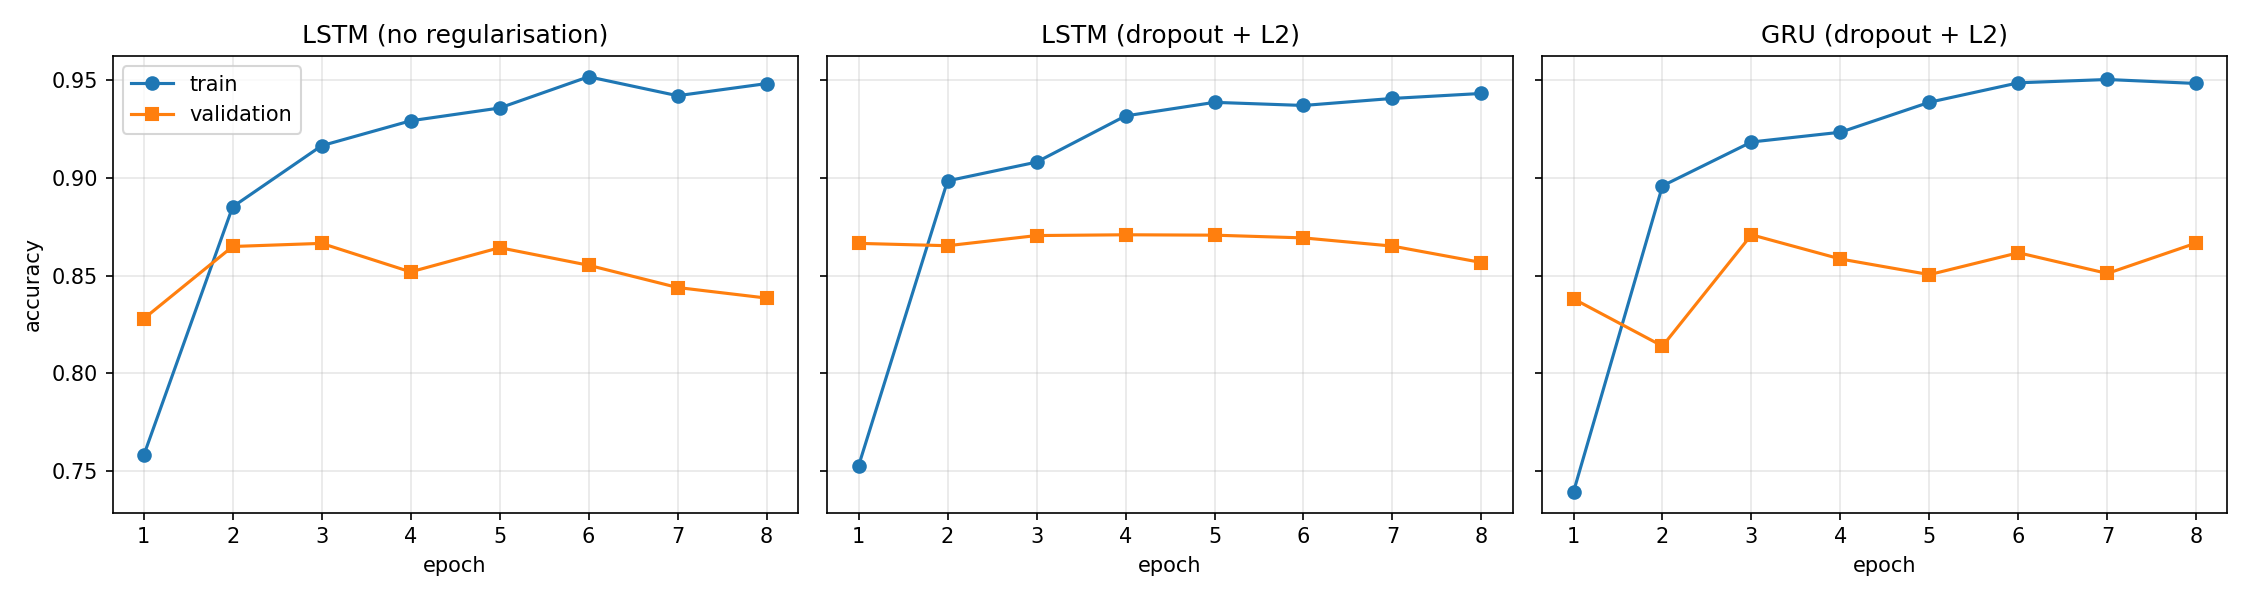

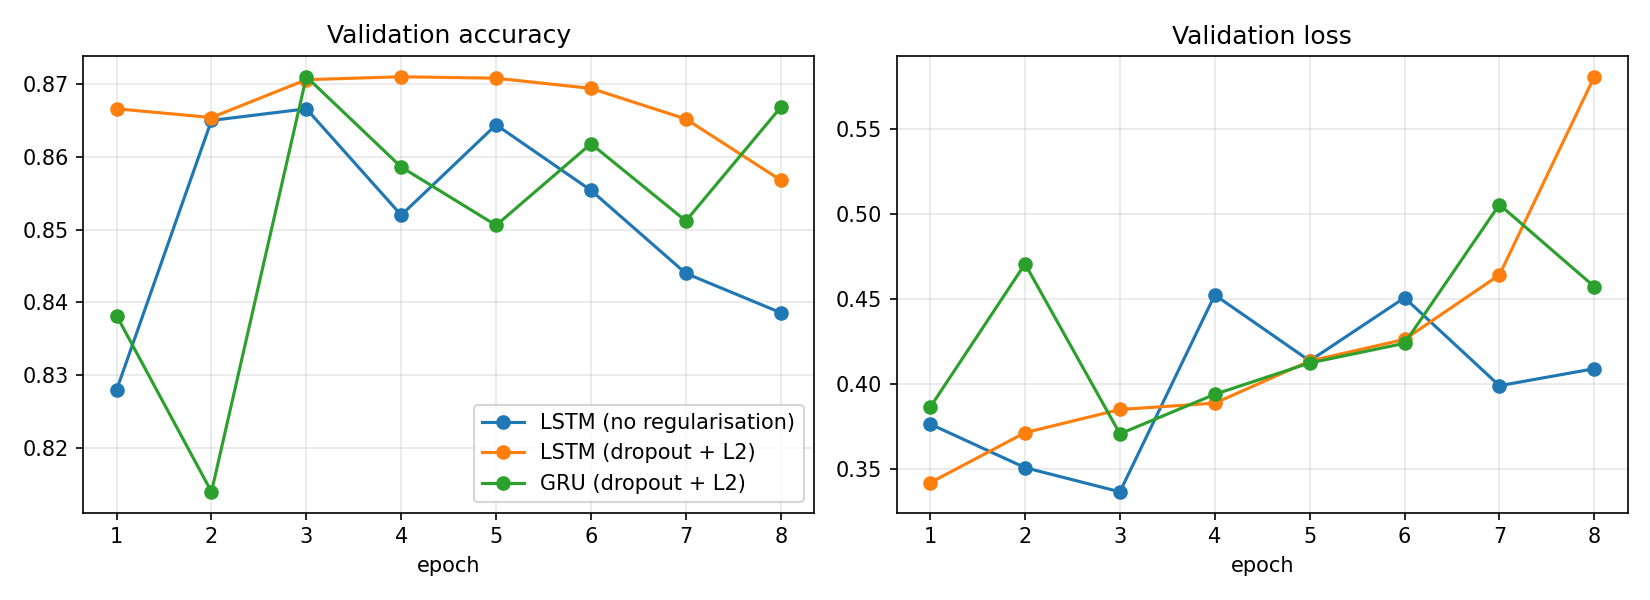

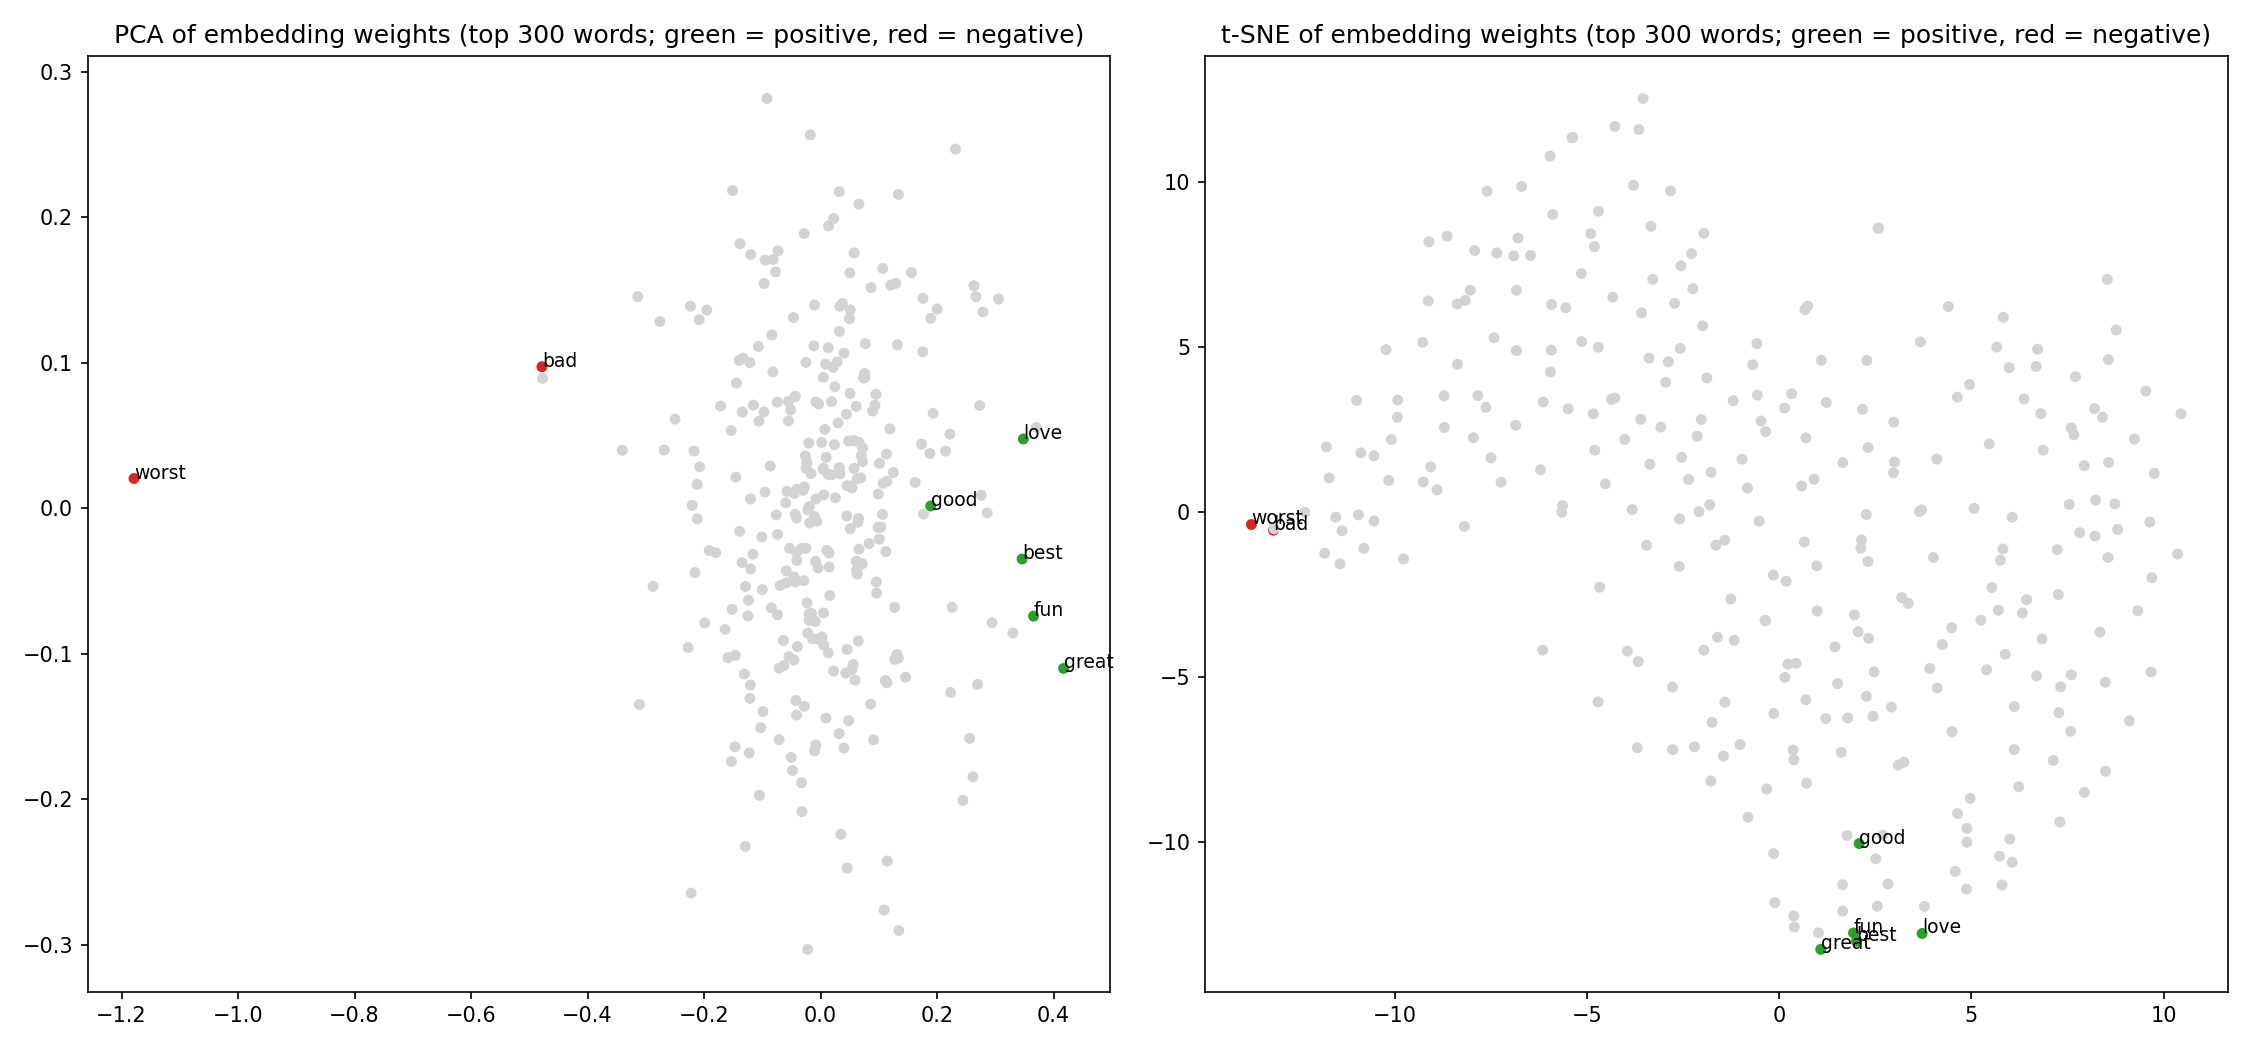

In [ ]:
from IPython.display import Image, display
for f in ['accuracy_curves.png','val_comparison.png','embeddings_pca_tsne.png']:
    display(Image('outputs/'+f))